In [1]:
import pandas as pd

In [3]:
df = pd.read_csv("dataset.csv")

In [4]:
df.head()

,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0


In [5]:
df.columns

Index(['Duration', 'Date', 'Pulse', 'Maxpulse', 'Calories'], dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB


In [7]:
df.shape

(32, 5)

In [8]:
df.isnull().sum()

,0
Duration,0
Date,1
Pulse,0
Maxpulse,0
Calories,2


In [9]:
df_clean = df.dropna()

In [10]:
df_clean.isnull().sum()

,0
Duration,0
Date,0
Pulse,0
Maxpulse,0
Calories,0


In [11]:
df["Calories"] = df["Calories"].fillna(df["Calories"].mean())

In [12]:
df.isnull().sum()

,0
Duration,0
Date,1
Pulse,0
Maxpulse,0
Calories,0


In [13]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [14]:
df.isnull().sum()

,0
Duration,0
Date,2
Pulse,0
Maxpulse,0
Calories,0


In [ ]:
df.isnull().sum()

In [15]:
df = df.dropna(subset=["Date"])

In [16]:
high_pulse = df[df["Pulse"] > 100]

high_pulse.head()

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0


In [17]:
high_calories = df[df["Calories"] > 300]

high_calories.head()

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
4,45,2020-12-05,117,148,406.0
6,60,2020-12-07,110,136,374.0


In [18]:
duration_60 = df[df["Duration"] == 60]

duration_60.head()

,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
5,60,2020-12-06,102,127,300.0
6,60,2020-12-07,110,136,374.0


In [19]:
df["Pulse_Difference"] = df["Maxpulse"] - df["Pulse"]

In [20]:
df["Calorie_Level"] = df["Calories"].apply(
    lambda x: "High" if x >= 300 else "Low"
)

In [21]:
df.describe()

,Duration,Date,Pulse,Maxpulse,Calories,Pulse_Difference
count,30.000000,30,30.000000,30.000000,30.000000,30.000000
mean,69.500000,2020-12-15 08:00:00,103.733333,129.100000,307.258667,25.366667
min,30.000000,2020-12-01 00:00:00,90.000000,101.000000,195.100000,-29.000000
25%,60.000000,2020-12-08 06:00:00,100.000000,120.750000,251.350000,22.000000
50%,60.000000,2020-12-14 12:00:00,103.000000,128.500000,300.000000,25.500000
75%,60.000000,2020-12-22 12:00:00,107.500000,132.750000,343.975000,28.000000
max,450.000000,2020-12-31 00:00:00,130.000000,175.000000,479.000000,66.000000
std,72.258516,NaN,8.042702,13.215325,65.029091,13.555717


In [22]:
df["Calories"].mean()

np.float64(307.25866666666667)

In [23]:
df["Pulse"].mean()

np.float64(103.73333333333333)

In [24]:
df["Pulse"].max()

130

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

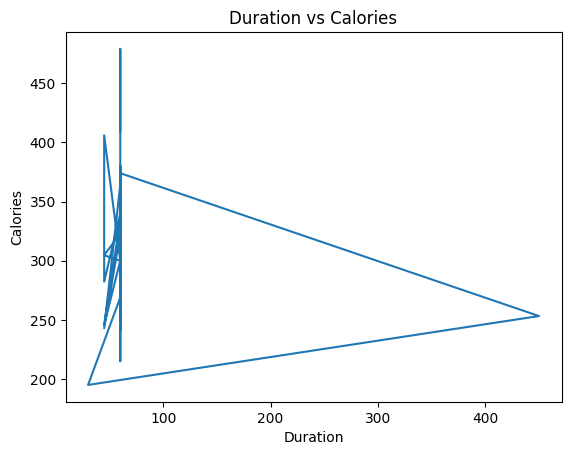

In [26]:
plt.plot(df["Duration"], df["Calories"])
plt.xlabel("Duration")
plt.ylabel("Calories")
plt.title("Duration vs Calories")
plt.show()

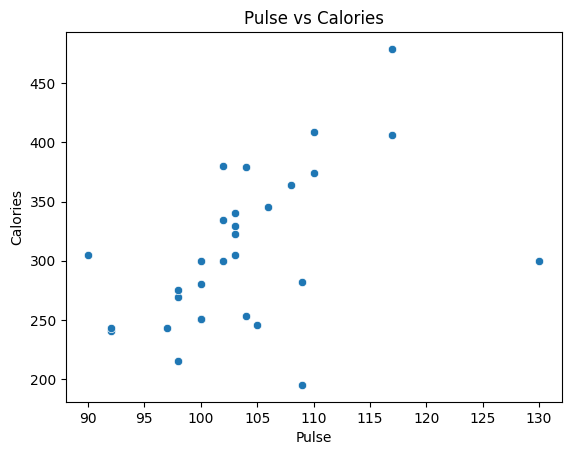

In [27]:
sns.scatterplot(x="Pulse", y="Calories", data=df)

plt.title("Pulse vs Calories")
plt.show()

In [28]:
df.to_csv("cleaned_week3_data.csv", index=False)